# Task 3: Model Refinement & Multimodal Integration

**Question:** do pre-trained / transformer representations of the news make our USD/IDR (JISDOR) direction forecast measurably better than the Task 2 pipeline?

This notebook is the reproducible record of every Task 3 experiment. It reads what `python -m src.run_task3` and `python -m src.analysis_task3` wrote to `reports/task3/`, so every number is the pipeline's own.

| § | Content |
|---|---|
| 1 | What Task 3 adds: four encoders, feature strategies, fusion designs |
| 2 | Feature extraction sanity checks (word vectors, FinBERT tone, topics, NER) |
| 3 | Representation comparison (static vs contextual, general vs domain) |
| 4 | Feature strategies: pooling, topics, entities |
| 5 | Fusion: early vs late vs attention network, fine-tuning |
| 6 | Tuning and the A / B / C ablation (with seeds and bootstrap intervals) |
| 7 | Embedding space: t-SNE of high- vs low-volatility days |
| 8 | Interpretability: SHAP, topics, biggest prediction shifts |
| 9 | Error analysis and distributions; drift; the magnitude target |
| 10 | Findings |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
REP, FIG, SPL = ROOT / "reports" / "task3", ROOT / "reports" / "task3" / "figures", ROOT / "data" / "splits" / "task3"
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
res = pd.read_csv(REP / "results.csv")
man = json.loads((REP / "manifest.json").read_text())
groups = json.loads((SPL / "feature_groups.json").read_text())
frame = pd.concat([pd.read_csv(SPL / f"{s}.csv", index_col=0, parse_dates=True) for s in ("train", "val", "test")]).sort_index()

def table(df, idx=("experiment", "model")):
    return (df.pivot_table(index=list(idx), columns="split", values="macro_f1")
              .reindex(columns=["val", "test"]).round(3).sort_values("val", ascending=False))

print("rows:", man["rows"], "| headlines:", f"{man['n_headlines']:,}", "| fit_before:", man["fit_before"])
print("encoders:", json.dumps(man["encoders"], indent=1))
print({g: len(c) for g, c in groups.items()})

rows: {'train': 726, 'val': 235, 'test': 240} | headlines: 119,100 | fit_before: 2024-08-30
encoders: {
 "glove": "sentence-transformers/average_word_embeddings_glove.6B.300d",
 "ppmi": "PPMI-SVD trained on our headlines",
 "minilm": "sentence-transformers/all-MiniLM-L6-v2",
 "finbert": "ProsusAI/finbert"
}
{'price': 10, 'market': 4, 'task1_news': 53, 'nlp': 46, 'emb_glove_mean': 16, 'emb_ppmi_mean': 16, 'emb_minilm_mean': 16, 'emb_minilm_decay': 16, 'emb_minilm_attention': 16, 'emb_finbert_mean': 16, 'emb_finbert_decay': 16, 'emb_finbert_attention': 16, 'finbert_sent': 13, 'topics': 40, 'entity': 16}


## 1. What Task 3 adds

Task 2 was limited to lexicons (VADER, Loughran-McDonald) and a TF-IDF we fitted ourselves. Task 3 adds four encoders, chosen as a 2 x 2 so each comparison isolates one design choice:

| | general-purpose | domain-specific |
|---|---|---|
| **static** (one vector per word) | GloVe 6B-300d | PPMI-SVD word vectors trained on our 2021-24 headlines (= Word2Vec's objective, Levy & Goldberg 2014) |
| **contextual** (vector depends on the sentence) | all-MiniLM-L6-v2 (sentence similarity) | FinBERT (ProsusAI, financial tone) |

Each headline becomes a vector; a day's vectors are pooled (mean, exponential decay, or salience attention), compressed with PCA fitted on training days, and shifted one trading day (news of day t-1 -> fix t), exactly like every Task 2 feature.

## 2. Feature extraction sanity checks

In [2]:
wv = ROOT / "data" / "interim" / "embeddings" / "ppmi_word_vectors.parquet"
if wv.exists():
    W = pd.read_parquet(wv)
    for w in ["war", "fed", "sanction", "oil", "tariff", "inflation"]:
        if w in W.index:
            s = W.values @ W.loc[w].values
            print(f"{w:>10} -> {', '.join(W.index[np.argsort(-s)[1:8]])}")
else:
    print("word vectors are in data/interim (not on GitHub); run src.run_task3 to rebuild")

       war -> invasion, ukraine, conflict, offensive, russia, putin, troop
       fed -> powell, ecb, boe, hawkish, boj, taper, rate
  sanction -> russia, embargo, russian, putin, belarusian, eurozone, regime
       oil -> crude, eia, refining, shipping, hellenic, output, refiner
    tariff -> subsidy, import, export, aluminum, curb, sugar, rice
 inflation -> rate, slowing, hike, fed, economist, recession, slower


In [3]:
print("PCA variance kept by 16 components (training days):")
display(pd.read_csv(REP / "pca_variance.csv").round(3))
print("Topics (k-means on MiniLM, labelled by class-based TF-IDF on training headlines):")
display(pd.read_csv(REP / "topic_labels.csv"))
print("NER: share of top-100 daily headlines that mention each watchlist group")
print(json.dumps(man["ner_coverage"], indent=1))

PCA variance kept by 16 components (training days):


,encoder,pooling,k,explained
0,glove,mean,16,0.543
1,ppmi,mean,16,0.680
2,minilm,mean,16,0.469
3,minilm,decay,16,0.749
4,minilm,attention,16,0.448
5,finbert,mean,16,0.622
6,finbert,decay,16,0.785
7,finbert,attention,16,0.648


Topics (k-means on MiniLM, labelled by class-based TF-IDF on training headlines):


,topic,train_headlines,share,top_words
0,0,4820,0.066391,"police, man, num, shooting, killed, arrested, death, officer"
1,1,3381,0.046570,"election, poll, vote, party, voter, bjp, win, modi"
2,2,3789,0.052190,"inflation, rate, dollar, price, pct, fed, rupee, num"
3,3,4518,0.062231,"ukraine, russia, russian, putin, war, nato, ukrainian, say"
4,4,3086,0.042507,"oil, price, gas, opec, fuel, united_states, crude, production"
5,5,5097,0.070207,"biden, trump, gop, republican, democrat, senate, house, num"
6,6,3899,0.053705,"stock, market, wall, asian, share, street, today, mixed"
7,7,4252,0.058567,"court, abortion, trump, judge, supreme, case, trial, law"
8,8,3891,0.053595,"num, star, not, new, film, book, show, taylor"
9,9,2168,0.029862,"strike, worker, union, pay, rail, contract, labor, deal"


NER: share of top-100 daily headlines that mention each watchlist group
{
 "us": 0.19738035264483628,
 "fed": 0.014693534844668345,
 "indonesia": 0.0014441645675902603,
 "china": 0.03486146095717884,
 "russia_ukraine": 0.07437447523089841,
 "middle_east": 0.07429051217464315,
 "central_banks": 0.018270361041141898,
 "any": 0.3414273719563392
}


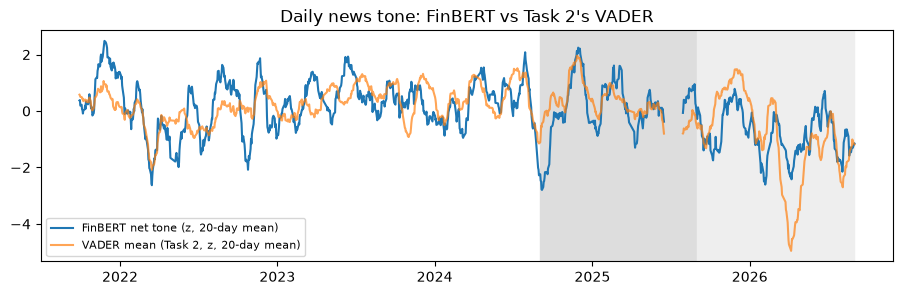

correlation of daily FinBERT net tone with VADER mean: 0.452


In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
fb = frame["t3_finbert_net"].rolling(20).mean()
vd = frame["nlp_vader_mean"].rolling(20).mean()
ax.plot(fb.index, (fb - fb.mean()) / fb.std(), label="FinBERT net tone (z, 20-day mean)")
ax.plot(vd.index, (vd - vd.mean()) / vd.std(), label="VADER mean (Task 2, z, 20-day mean)", alpha=0.7)
for s, c in (("val", "#ddd"), ("test", "#eee")):
    d = frame.index[frame["split"] == s]; ax.axvspan(d.min(), d.max(), color=c, zorder=0)
ax.legend(fontsize=8); ax.set_title("Daily news tone: FinBERT vs Task 2's VADER")
plt.show()
print("correlation of daily FinBERT net tone with VADER mean:",
      round(frame[["t3_finbert_net", "nlp_vader_mean"]].corr().iloc[0, 1], 3))

## 3. Representation comparison

Each encoder's daily-mean PCA block is added to Model A (price + overnight markets) with the Task 2 grid (early fusion), and also used **alone** (text only). Macro-F1, chosen on validation, scored once on test. Chance for three balanced classes is about 0.33.

In [5]:
display(table(res.loc[res["stage"] == "1_representation"]))
display(table(res.loc[res["stage"] == "0_task2"]))

split                                 val   test
experiment                  model               
A + emb_finbert_mean        xgb     0.462  0.487
A + emb_ppmi_mean           xgb     0.460  0.498
A + emb_glove_mean          logreg  0.456  0.418
A + emb_finbert_mean        logreg  0.451  0.454
A + emb_glove_mean          xgb     0.450  0.457
A + emb_minilm_mean         xgb     0.442  0.463
                            logreg  0.440  0.416
A + emb_ppmi_mean           logreg  0.415  0.433
text only: emb_glove_mean   logreg  0.357  0.302
text only: emb_finbert_mean logreg  0.310  0.321
text only: emb_minilm_mean  logreg  0.275  0.305
text only: emb_ppmi_mean    logreg  0.247  0.363

split                                   val   test
experiment                    model               
B: A + Task 2 NLP             logreg  0.509  0.388
                              xgb     0.493  0.427
A: time series (price+market) logreg  0.439  0.458
                              xgb     0.435  0.457
A0: price only                logreg  0.403  0.321
                              xgb     0.372  0.337

## 4. Feature strategies: temporal pooling, FinBERT tone, topics, entities

In [6]:
display(table(res.loc[res["stage"] == "2_strategy"]))

split                                      val   test
experiment                       model               
A + finbert_sent                 xgb     0.465  0.455
A + emb_minilm_decay             xgb     0.459  0.499
A + emb_minilm_attention         xgb     0.459  0.414
A + finbert_sent                 logreg  0.456  0.422
A + topics                       xgb     0.451  0.432
                                 logreg  0.450  0.421
A + emb_finbert_attention        logreg  0.445  0.386
                                 xgb     0.439  0.456
A + emb_finbert_decay            logreg  0.438  0.424
                                 xgb     0.437  0.430
A + entity                       xgb     0.430  0.463
A + emb_minilm_attention         logreg  0.420  0.442
A + entity                       logreg  0.410  0.452
A + emb_minilm_decay             logreg  0.409  0.429
text only: emb_finbert_attention logreg  0.342  0.247
text only: finbert_sent          logreg  0.338  0.302
text only: emb_minilm_attention  logreg  0.337  0.332
text only: topics                logreg  0.317  0.332
text only: emb_finbert_decay     logreg  0.305  0.282
text only: entity                logreg  0.286  0.350
text only: emb_minilm_decay      logreg  0.280  0.291

## 5. Fusion: early vs late vs attention network

*Late fusion* blends the probabilities of the time-series model and a text-only model, `log p = (1-w) log p_time + w log p_text`, with `w` picked on validation. `w = 0` means "ignore the news". The *attention network* reads the top-64 headline vectors of the day directly and learns which to attend to. *Fine-tuned MiniLM* is a transformer trained on our own labels, used only through late fusion so it is never scored on days it was trained on.

In [7]:
display(table(res.loc[(res["stage"] == "3_fusion") & ~res["experiment"].str.contains("seed")]))
lw = pd.read_csv(REP / "late_fusion_weights.csv")
chosen = lw.loc[lw.groupby("experiment")["val_macro_f1"].idxmax(), ["experiment", "w", "val_macro_f1"]]
print("weight given to text by late fusion (chosen on validation):")
display(chosen.sort_values("w", ascending=False).round(3))
ft = ROOT / "data" / "interim" / "embeddings" / "finetune_headline_accuracy.json"
if ft.exists():
    print("fine-tuned MiniLM, headline-level accuracy:", ft.read_text())
seeds = res.loc[res["experiment"].str.contains("attention_net_.*_seed", regex=True)]
print("attention network, per seed:")
display(seeds.pivot_table(index="experiment", columns="split", values="macro_f1").round(3))

,split,val,test
experiment,model,,
late: A(logreg) + emb_finbert_mean,late,0.462,0.461
late: A(logreg) + emb_glove_mean,late,0.462,0.424
late: A(logreg) + emb_finbert_attention,late,0.458,0.334
late: A(logreg) + topics,late,0.457,0.452
late: A(logreg) + finbert_sent,late,0.453,0.454
late: A(logreg) + fine-tuned MiniLM,late,0.450,0.453
late: A(logreg) + entity,late,0.449,0.470
late: A(logreg) + emb_minilm_decay,late,0.447,0.455
late: A(logreg) + emb_ppmi_mean,late,0.446,0.454


weight given to text by late fusion (chosen on validation):


,experiment,w,val_macro_f1
55,late: A(logreg) + emb_finbert_attention,0.6,0.458
68,late: A(logreg) + topics,0.5,0.457
46,late: A(logreg) + emb_finbert_decay,0.4,0.444
38,late: A(logreg) + emb_finbert_mean,0.3,0.462
3,late: A(logreg) + emb_glove_mean,0.3,0.462
59,late: A(logreg) + finbert_sent,0.3,0.453
16,late: A(logreg) + emb_minilm_mean,0.2,0.440
72,late: A(logreg) + entity,0.2,0.449
79,late: A(logreg) + fine-tuned MiniLM,0.2,0.450
22,late: A(logreg) + emb_minilm_decay,0.1,0.447


fine-tuned MiniLM, headline-level accuracy: {
  "n_train_headlines": 23232,
  "n_val_headlines": 7168,
  "train_accuracy": 0.3621728650137741,
  "val_accuracy": 0.3720703125,
  "val_majority_share": 0.41964285714285715
}
attention network, per seed:


split,test,val
experiment,,
attention_net_finbert_seed123,0.393,0.446
attention_net_finbert_seed2024,0.389,0.456
attention_net_finbert_seed42,0.396,0.448
attention_net_minilm_seed123,0.427,0.443
attention_net_minilm_seed2024,0.440,0.454
attention_net_minilm_seed42,0.424,0.452


## 6. Tuning and the ablation matrix

Model C is the Task 3 text configuration with the best **validation** macro-F1, re-tuned on a wider grid (PCA size, regularisation, tree depth / count / learning rate). The ablation then compares:

* **A0**: price history only  · **A**: time series only (price + overnight markets, the Task 2 baseline)
* **B**: A + Task 2 basic NLP (46 lexicon / TF-IDF features)
* **C**: A + Task 3 refined text features · **B+C**: both

XGBoost is run with 3 seeds (mean ± std); logistic regression is deterministic.

best Task 3 config on validation: {'experiment': 'A + finbert_sent', 'model': 'xgb', 'val_macro_f1': 0.4648067510247939}
Model C per model family: [
 {
  "model": "logreg",
  "C_block": "finbert_sent",
  "C_params": {
   "C": 0.01
  },
  "val_macro_f1": 0.4559851100551946
 },
 {
  "model": "xgb",
  "C_block": "finbert_sent",
  "C_params": {
   "max_depth": 2,
   "n_estimators": 300,
   "learning_rate": 0.05,
   "min_child_weight": 1
  },
  "val_macro_f1": 0.4648067510247939
 }
]


,block,k,model,params,val_macro_f1
0,finbert_sent,NaN,xgb,"{""max_depth"": 2, ""n_estimators"": 300, ""learning_rate"": 0.05, ""min_child_weight"": 1}",0.465
1,finbert_sent,NaN,logreg,"{""C"": 0.01}",0.456


macro_f1        accuracy        directional_hit_rate       
                     mean    std     mean    std                 mean    std
set model  split                                                            
A   logreg test     0.458    NaN    0.458    NaN                0.528    NaN
           val      0.439    NaN    0.481    NaN                0.526    NaN
    xgb    test     0.440  0.014    0.442  0.014                0.482  0.005
           val      0.439  0.006    0.489  0.007                0.547  0.004
A0  logreg test     0.321    NaN    0.338    NaN                0.330    NaN
           val      0.403    NaN    0.417    NaN                0.471    NaN
    xgb    test     0.351  0.014    0.353  0.015                0.340  0.018
           val      0.371  0.005    0.403  0.007                0.444  0.014
B   logreg test     0.388    NaN    0.392    NaN                0.485    NaN
           val      0.509    NaN    0.532    NaN                0.538    NaN
    xgb    test     0.431  0.007    0.428  0.009                0.525  0.011
           val      0.479  0.014    0.513  0.016                0.540  0.019
B+C logreg test     0.403    NaN    0.404    NaN                0.473    NaN
           val      0.414    NaN    0.455    NaN                0.487    NaN
    xgb    test     0.434  0.011    0.431  0.010                0.516  0.017
           val      0.450  0.034    0.485  0.027                0.523  0.033
C   logreg test     0.422    NaN    0.421    NaN                0.489    NaN
           val      0.456    NaN    0.502    NaN                0.530    NaN
    xgb    test     0.445  0.009    0.444  0.009                0.479  0.008
           val      0.443  0.022    0.479  0.022                0.529  0.010

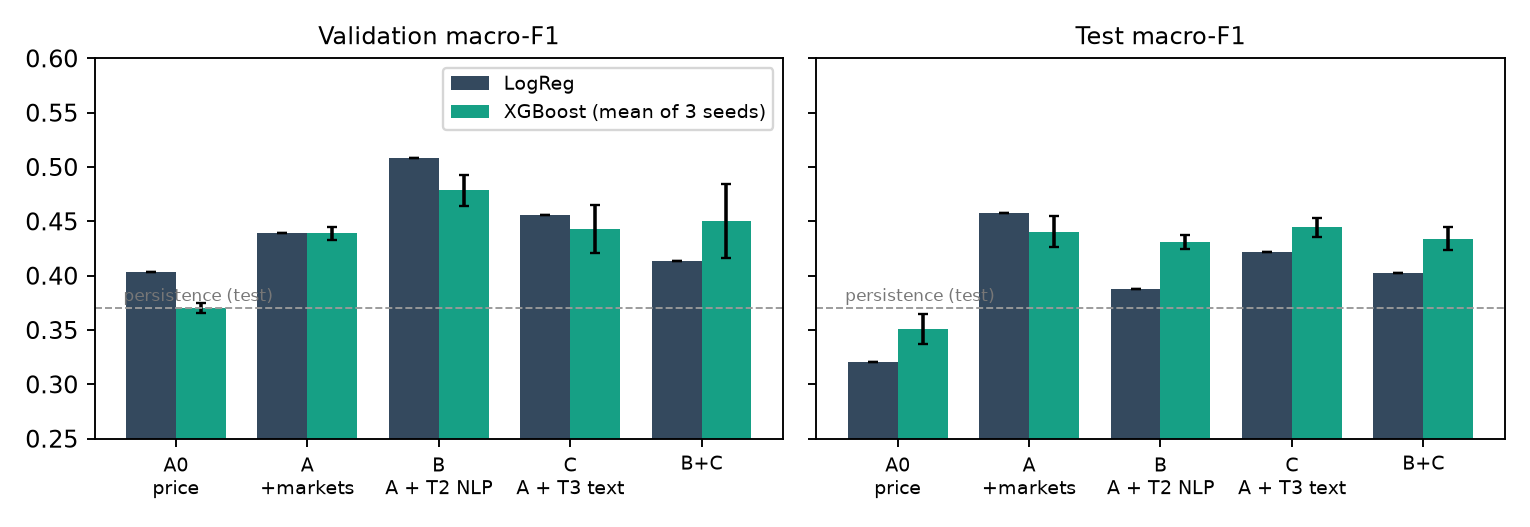

Block-bootstrap (10-day blocks) 95% intervals on TEST macro-F1 gains:


,model,base,new,f1_base,f1_new,gain,ci_low,ci_high,p_no_gain
0,logreg,A,B,0.458,0.388,-0.070,-0.163,0.037,0.907
1,logreg,A,C,0.458,0.422,-0.036,-0.078,0.004,0.961
2,logreg,B,C,0.388,0.422,0.034,-0.080,0.134,0.259
3,logreg,A,B+C,0.458,0.403,-0.055,-0.135,0.038,0.887
4,xgb,A,B,0.457,0.427,-0.030,-0.108,0.033,0.838
5,xgb,A,C,0.457,0.455,-0.002,-0.074,0.056,0.597
6,xgb,B,C,0.427,0.455,0.027,-0.041,0.100,0.221
7,xgb,A,B+C,0.457,0.432,-0.025,-0.109,0.053,0.733
8,xgb,A,best-on-val: A + finbert_sent,0.458,0.455,-0.003,-0.065,0.063,0.576


Secondary task, next-day return (regression):


directional_accuracy          rmse       
split                            test    val   test    val
experiment model                                          
A          ridge                0.651  0.658  0.264  0.352
           xgb                  0.647  0.662  0.273  0.362
B          ridge                0.609  0.667  0.269  0.354
           xgb                  0.668  0.654  0.264  0.362
C          ridge                0.626  0.620  0.268  0.356
           xgb                  0.647  0.637  0.274  0.364

In [8]:
print("best Task 3 config on validation:", man["best_on_validation"])
print("Model C per model family:", json.dumps(man["model_C"], indent=1))
display(pd.read_csv(REP / "tuning.csv").head(10).round(3))
abl = res.loc[res["stage"] == "5_ablation"].copy()
abl["set"] = abl["experiment"].str.split("|").str[0]
summary = (abl.groupby(["set", "model", "split"])[["macro_f1", "accuracy", "directional_hit_rate"]]
              .agg(["mean", "std"]).round(3))
display(summary)
display(Image(FIG / "ablation.png"))
print("Block-bootstrap (10-day blocks) 95% intervals on TEST macro-F1 gains:")
display(pd.read_csv(REP / "ablation_gain.csv").round(3))
print("Secondary task, next-day return (regression):")
display(pd.read_csv(REP / "regression.csv").pivot_table(index=["experiment", "model"], columns="split",
        values=["rmse", "directional_accuracy"]).round(3))

## 7. Embedding space: headlines before high- vs low-volatility fixes

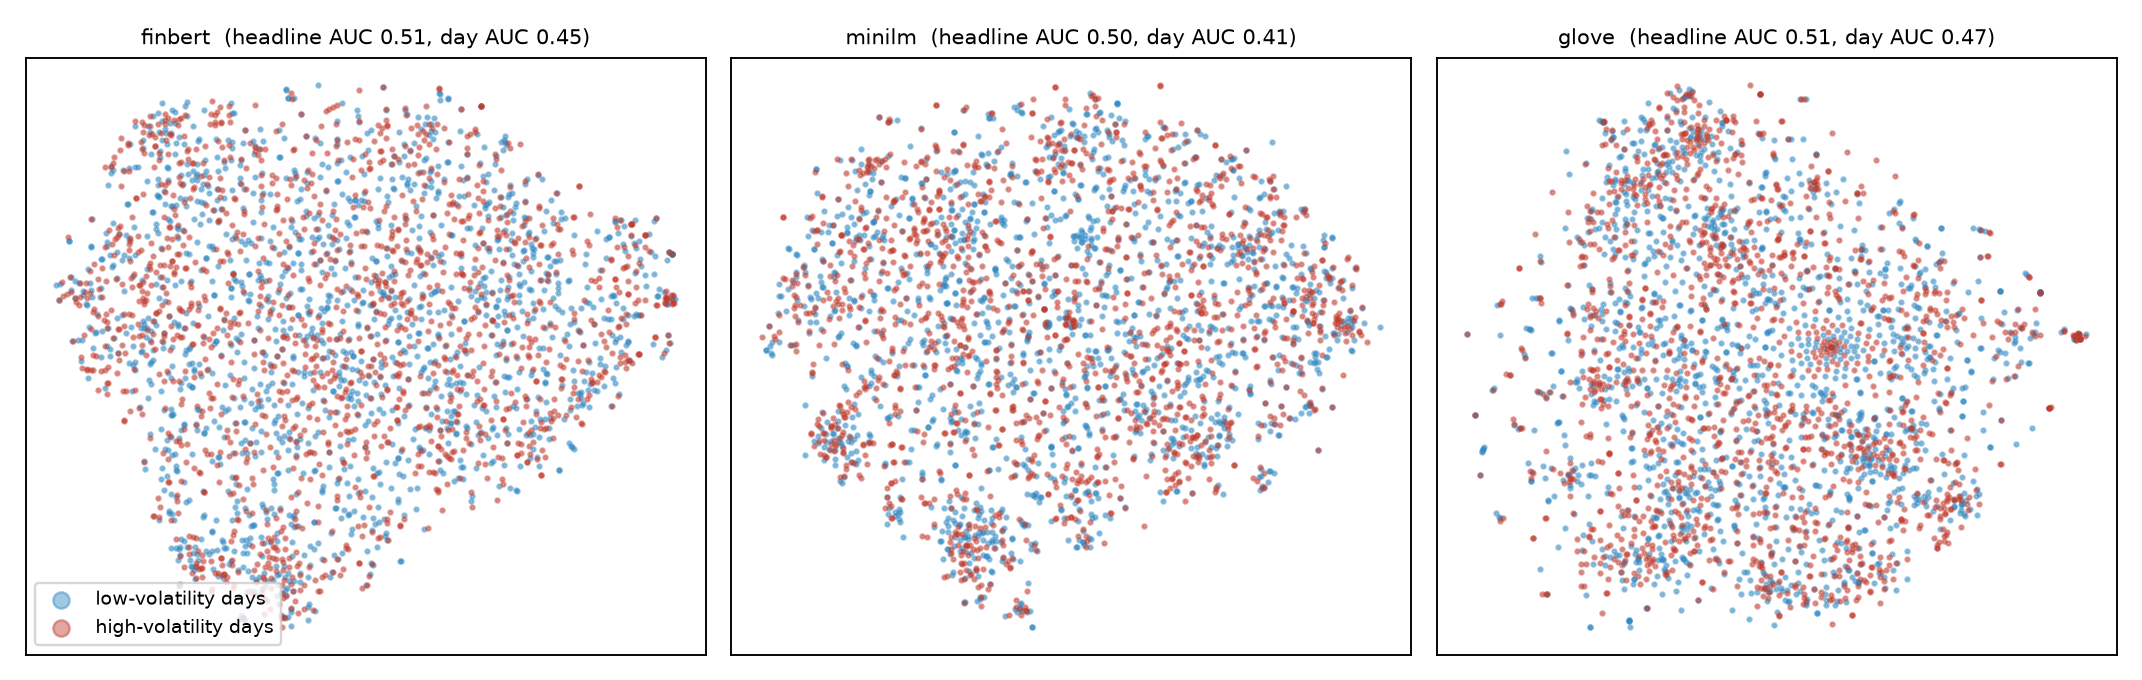

,encoder,headline_auc,day_auc,n_high_days,n_low_days
0,finbert,0.514,0.454,109,109
1,minilm,0.499,0.412,109,109
2,glove,0.511,0.470,109,109


In [9]:
display(Image(FIG / "tsne_volatility.png"))
display(pd.read_csv(REP / "analysis_vol_separability.csv").round(3))

## 8. Interpretability: what drives Model C?

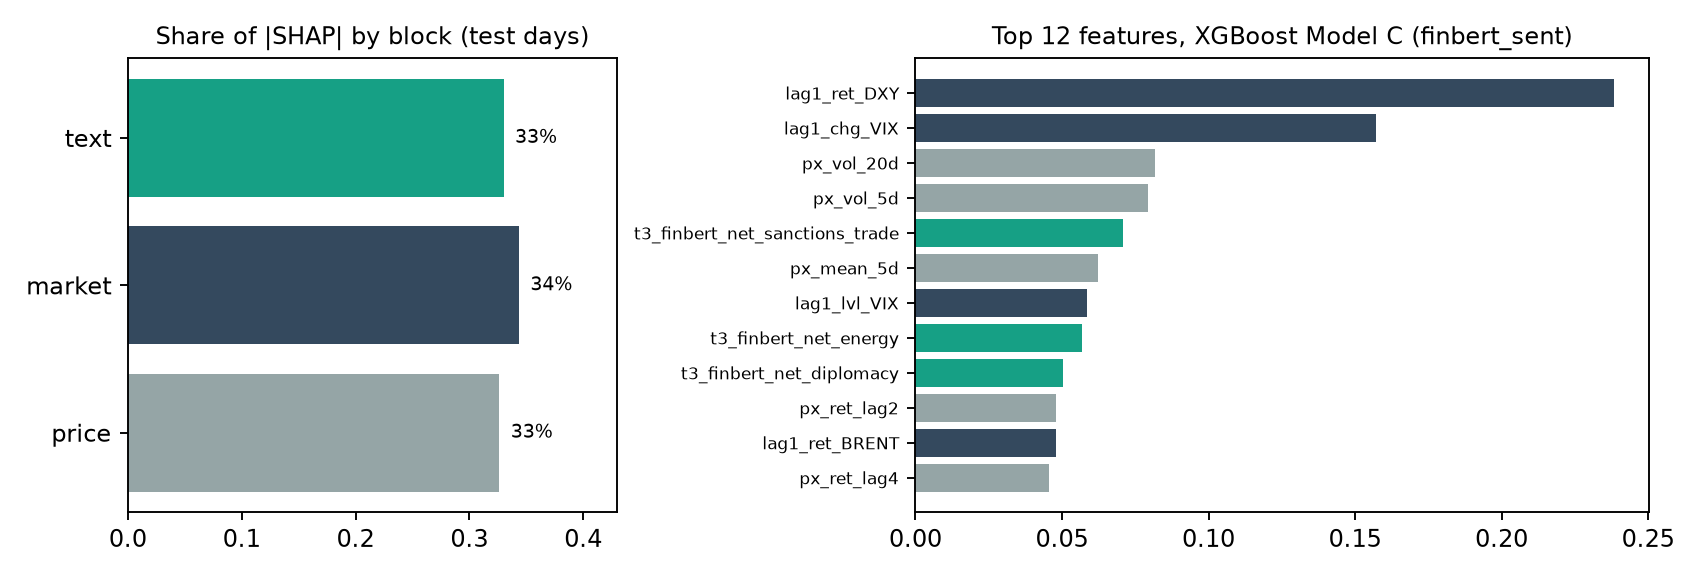

Topics most related to the SIZE of the next move (training days, Spearman):


,feature,top_words,rho_abs_return,p_abs_return,rho_return,p_return
9,t3_topic_share_09,"strike, worker, union, pay, rail, contract, labor, deal",0.122,0.001,0.017,0.639
14,t3_topic_share_14,"covid, vaccine, pandemic, health, num, mandate, care, cancer",-0.108,0.003,-0.046,0.218
12,t3_topic_share_12,"china, korea, united_states, iran, north, trade, chinese, taiwan",-0.077,0.037,0.007,0.843
6,t3_topic_share_06,"stock, market, wall, asian, share, street, today, mixed",-0.073,0.048,-0.043,0.249
0,t3_topic_share_00,"police, man, num, shooting, killed, arrested, death, officer",0.069,0.063,0.011,0.758
37,t3_topic_tone_17,"tax, debt, bill, budget, money, spending, plan, cut",-0.069,0.072,-0.075,0.048
10,t3_topic_share_10,"israel, gaza, israeli, hamas, palestinian, netanyahu, war, hostage",0.067,0.073,-0.012,0.754
34,t3_topic_tone_14,"covid, vaccine, pandemic, health, num, mandate, care, cancer",0.066,0.102,0.025,0.543


,block,n_features,sig_direction,sig_magnitude,expected_by_chance
0,nlp,46,1,10,2.30
1,emb_glove_mean,16,1,3,0.80
2,emb_ppmi_mean,16,4,2,0.80
3,emb_minilm_mean,16,2,2,0.80
4,emb_minilm_decay,16,1,2,0.80
5,emb_minilm_attention,16,1,2,0.80
6,emb_finbert_mean,16,0,3,0.80
7,emb_finbert_decay,16,0,3,0.80
8,emb_finbert_attention,16,1,2,0.80
9,finbert_sent,13,0,0,0.65


Test days where Model C moved furthest from Model A (XGBoost):


,date,news_bucket,shift,true,pred_A,pred_C,top_headlines
0,2026-07-20,2026-07-17,0.300435,UP,FLAT,DOWN,Latest Forecast Predicts Large COLA Increase For Social Security Recipients (x26) [FinBERT net +0.84] || U...
1,2026-01-20,2026-01-19,0.297465,UP,UP,FLAT,European leaders warn Trump's Greenland tariffs threaten 'dangerous downward spiral' (x13) [FinBERT net -0...
2,2025-09-26,2025-09-25,0.287013,UP,FLAT,UP,Just Stop Oil protesters guilty after latex poured on Tesla robot (x15) [FinBERT net -0.55] || Ukraine's Z...
3,2026-06-25,2026-06-24,0.282542,FLAT,DOWN,DOWN,Senate Votes To Limit Trump's Iran War Powers (x16) [FinBERT net -0.10] || Oil prices hit lows not seen si...
4,2025-11-07,2025-11-06,0.282388,FLAT,DOWN,FLAT,PM vows to 'stand up for our values and future' at Cop30 with new power deals (x18) [FinBERT net +0.78] ||...
5,2025-12-03,2025-12-02,0.266505,FLAT,FLAT,DOWN,US envoy to meet Putin for Ukraine peace plan talks (x17) [FinBERT net +0.08] || UK growth facing headwind...


Headlines the attention network focused on most (test days, highest weight):


,date,news_bucket,attention,headline
37,2025-10-23,2025-10-22,0.239308,Six killed in massive Russian drone and missile attack on Ukraine - officials
201,2026-07-07,2026-07-06,0.211275,Ukrainian drones hit St Petersburg region oil terminal
31,2025-10-15,2025-10-14,0.210746,Seven hurt as Russian aerial attack hits Ukrainian hospital
48,2025-11-07,2025-11-06,0.206158,Ukraine says it has hit a major Russian oil refinery with long-range drones
49,2025-11-10,2025-11-07,0.201642,Russian drone strike on Ukraine tower block kills three
115,2026-02-18,2026-02-13,0.184825,Ukrainian drone strike sparks fires at Russian Black Sea port
68,2025-12-05,2025-12-04,0.177371,Putin Launches Massive Attack On Ukraine After Rejecting US Peace Deal
232,2026-08-20,2026-08-19,0.175833,Ukraine aims drone blitz at Moscow while Russian missiles kill 10 in village


In [10]:
if (FIG / "shap_model_c.png").exists():
    display(Image(FIG / "shap_model_c.png"))
tc = pd.read_csv(REP / "analysis_topic_correlation.csv")
print("Topics most related to the SIZE of the next move (training days, Spearman):")
display(tc.reindex(tc["rho_abs_return"].abs().sort_values(ascending=False).index).head(8)
          [["feature", "top_words", "rho_abs_return", "p_abs_return", "rho_return", "p_return"]].round(3))
display(pd.read_csv(REP / "analysis_feature_correlations.csv"))
print("Test days where Model C moved furthest from Model A (XGBoost):")
display(pd.read_csv(REP / "analysis_prediction_shifts_xgb.csv").head(6))
if (REP / "attention_top_headlines.csv").exists():
    at = pd.read_csv(REP / "attention_top_headlines.csv")
    print("Headlines the attention network focused on most (test days, highest weight):")
    display(at.sort_values("attention", ascending=False).head(8))

## 9. Error analysis, error distributions, drift

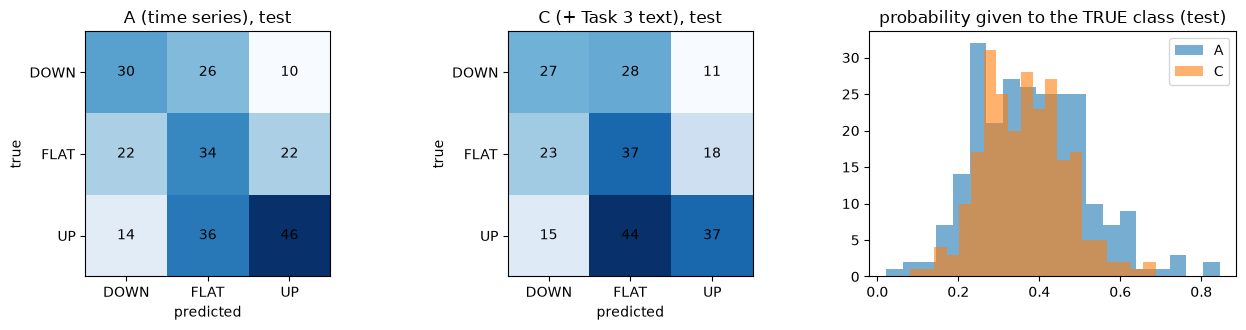

{'n_test': 240, 'both_right': 94, 'only_C_right': 7, 'only_A_right': 16, 'both_wrong': 123, 'A_false_signals': 68, 'C_false_signals': 67, 'false_signals_fixed_by_C': 5, 'mcnemar_p': 0.0931396484375}


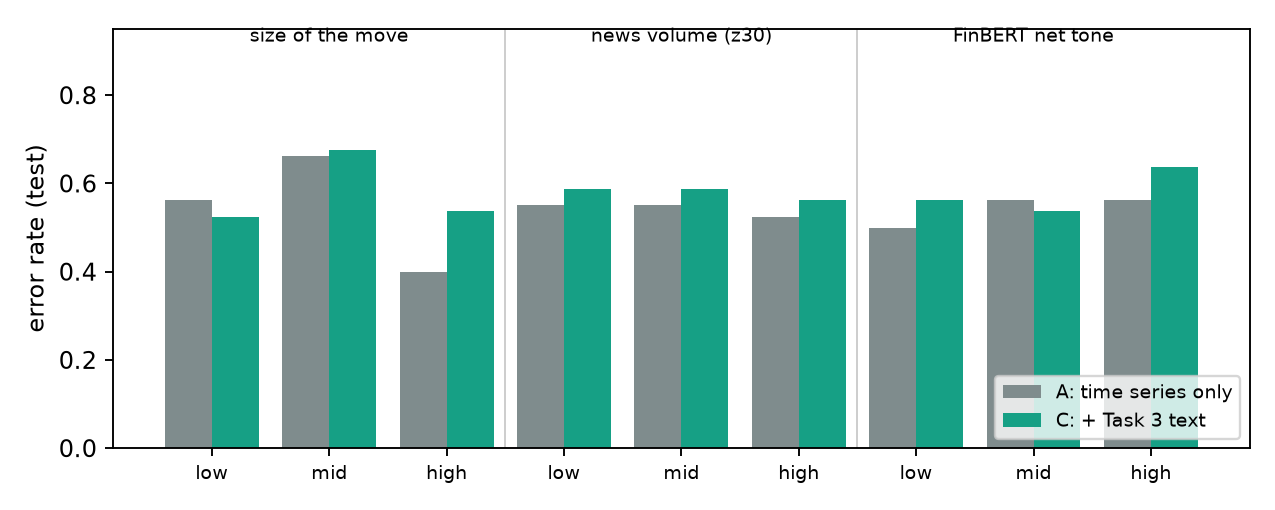

,kind,date,true,return,pred_A,pred_C,top_headlines
0,helped,2025-10-30,FLAT,0.054101,UP,FLAT,Man Accused Of Stabbing 2 Teens With Metal Fork During Flight (x16) [FinBERT net -0.78] || Rapist former M...
1,helped,2025-10-13,FLAT,-0.030152,UP,FLAT,Trump says 'there seems to be no reason' to meet China's Xi during Asia trip (x17) [FinBERT net +0.05] || ...
2,helped,2025-10-20,FLAT,-0.030143,DOWN,FLAT,Government unveils national plan to recruit workers for energy transition (x17) [FinBERT net +0.49] || Ind...
3,helped,2025-11-05,FLAT,0.029893,UP,FLAT,Coalition's climate change policy fight 'unavoidable' (x12) [FinBERT net -0.86] || Public workers could be...
4,helped,2026-07-29,FLAT,-0.005529,DOWN,FLAT,Trump demands Senate cancel August break until it passes voting bill (x10) [FinBERT net -0.73] || Trump re...
5,hurt,2026-05-18,UP,0.966960,UP,FLAT,President Trump Arrives In China For High (x36) [FinBERT net +0.04] || Budget brawl escalates over rival t...
6,hurt,2026-08-10,DOWN,-0.660919,DOWN,FLAT,One Nation's Farrer MP David Farley on first 100 days in Canberra (x23) [FinBERT net +0.06] || Indian mark...
7,hurt,2026-01-28,DOWN,-0.465339,DOWN,FLAT,Gold Price Reaches New All (x42) [FinBERT net +0.43] || Findings of the 2026 Canadian State of Restaurants...
8,hurt,2026-02-06,UP,0.361879,UP,FLAT,Popular Pizza Chain Closing 100s Of Restaurants Across The US (x36) [FinBERT net -0.16] || Claiming India ...
9,hurt,2026-03-16,UP,0.330150,UP,FLAT,When Gas Prices Will Drop Back Down To Normal Revealed (x72) [FinBERT net -0.76] || Global stocks in meltd...


In [11]:
from sklearn.metrics import confusion_matrix
pred = pd.read_csv(REP / "predictions.csv", index_col=0, parse_dates=True)
te = pred.loc[pred["split"] == "test"]
cls = ["DOWN", "FLAT", "UP"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, key, title in ((axes[0], "A|seed42|logreg", "A (time series)"), (axes[1], "C|seed42|logreg", "C (+ Task 3 text)")):
    p = np.asarray(cls)[te[[f"{key}|{c}" for c in cls]].to_numpy().argmax(1)]
    cm = confusion_matrix(te["y_direction"], p, labels=cls)
    ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(3), cls); ax.set_yticks(range(3), cls)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title}, test")
for key, lab in (("A|seed42|logreg", "A"), ("C|seed42|logreg", "C")):
    P = te[[f"{key}|{c}" for c in cls]].to_numpy()
    true_p = P[np.arange(len(te)), pd.Categorical(te["y_direction"], categories=cls).codes]
    axes[2].hist(true_p, bins=20, alpha=0.6, label=lab)
axes[2].set_title("probability given to the TRUE class (test)"); axes[2].legend()
plt.tight_layout(); plt.show()
print(json.loads((REP / "analysis_error_summary.json").read_text()))
display(Image(FIG / "error_by_regime.png"))
display(pd.read_csv(REP / "analysis_error_examples.csv"))

In [12]:
print("Adversarial validation: ROC-AUC of telling a TRAIN day from a TEST day from each block alone")
display(pd.read_csv(REP / "analysis_drift.csv").round(3))
print("Does text predict the SIZE of tomorrow's move? |return| regression (Ridge), test")
display(pd.read_csv(REP / "analysis_magnitude.csv").round(4))

Adversarial validation: ROC-AUC of telling a TRAIN day from a TEST day from each block alone


,block,n_features,train_vs_test_auc
0,price,10,0.553
1,market,4,0.513
2,price+market,14,0.608
3,nlp,46,0.993
4,emb_glove_mean,16,0.882
5,emb_ppmi_mean,16,0.957
6,emb_minilm_mean,16,0.931
7,emb_finbert_mean,16,0.935
8,emb_finbert_decay,16,0.999
9,emb_finbert_attention,16,0.838


Does text predict the SIZE of tomorrow's move? |return| regression (Ridge), test


,set,alpha,val_rmse,test_rmse,test_r2_vs_mean,test_spearman,rmse_gain_ci_low,rmse_gain_ci_high,p_no_gain
0,A,1000.0,0.2518,0.1865,0.0285,0.0139,NaN,NaN,NaN
1,B,1000.0,0.2518,0.1951,-0.0625,-0.0532,-0.0149,-0.0035,1.000
2,C: A + emb_glove_mean,100.0,0.2468,0.1866,0.0281,0.0147,-0.0050,0.0051,0.560
3,C: A + emb_ppmi_mean,100.0,0.2491,0.1867,0.0269,0.1349,-0.0051,0.0045,0.539
4,C: A + emb_minilm_mean,1000.0,0.2461,0.1864,0.0297,-0.0339,-0.0031,0.0043,0.487
5,C: A + emb_finbert_mean,1000.0,0.2502,0.1849,0.0459,0.0768,-0.0007,0.0043,0.081
6,C: A + finbert_sent,1000.0,0.2506,0.1860,0.0343,0.0677,-0.0024,0.0033,0.337
7,C: A + topics,1000.0,0.2507,0.1859,0.0347,0.0169,-0.0024,0.0035,0.318
8,C: A + entity,1000.0,0.2520,0.1889,0.0041,0.0955,-0.0057,0.0010,0.889
9,C: A + emb_finbert_decay,1000.0,0.2526,0.1869,0.0244,0.0223,-0.0034,0.0021,0.627


## 10. Findings

1. **Transformer representations did not measurably improve direction forecasting.** Model C (A + FinBERT tone, the best Task 3 configuration on *validation*) scores 0.445 ± 0.009 test macro-F1 with XGBoost (3 seeds) vs 0.440 for Model A, and 0.422 vs 0.458 with logistic regression. Every block-bootstrap interval for C vs A includes zero.
2. **They are better than Task 2's basic NLP.** C beats B by about +0.03 with both models. B overfits the validation year the most (0.509 val -> 0.388 test).
3. **Domain-specific > general and contextual > static, but by little:** with XGBoost, FinBERT 0.487 vs MiniLM 0.463, and corpus-trained PPMI 0.498 vs GloVe 0.457. These variants were not the validation winners, so they are reported, not selected. Text alone is near chance (0.25-0.36).
4. **Fusion:** late fusion gives the news a weight of 0.1-0.5 on validation, but test stays within about ±0.02 of A. The attention network overfits (test 0.39-0.42). Fine-tuned MiniLM reaches 37% headline accuracy, below the 42% majority share: the labels are too noisy.
5. **Why:** the time-series features look alike in train and test (adversarial AUC 0.51-0.61), while every text block identifies the period (0.83-0.99). News semantics drift from era to era (COVID, Ukraine, Gaza -> tariffs, Iran). In t-SNE, headlines before high- and low-volatility days are indistinguishable (probe AUC about 0.5).
6. **Errors:** the text makes the model more cautious. It fixes false UP/DOWN calls on truly FLAT days (5 cases), but hedges to FLAT on big-move days (error 0.54 vs 0.40 in the top move tercile). McNemar p = 0.09.
7. **SHAP:** Model C splits its weight evenly across markets 34%, price 33% and FinBERT tone 33%. The most-used text features are the tone of sanctions/trade, energy and diplomacy news. The attention network focuses on Russia-Ukraine strikes on energy sites.

**Next (Task 4):** rolling re-training against drift; use news for the *size* of the move or as a confidence gate; add Indonesia-specific sources (only 0.1% of top headlines mention Indonesia).